In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *



In [2]:
domainM='GRq'
ds_RF_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/daily/'+
    'RF_day_MARv3.14_ER5_spin2_GRq_1980-2024.nc')['RF']#.sel(ZTQLEV=2)
ds_RF= ds_RF_raw.rename({'TIME': 'time'})
#units_TTZ=ds_TTZ.units


In [3]:
ds_SF_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/daily/'+
    'SF_day_MARv3.14_ER5_spin2_GRq_1980-2024.nc')['SF']#.sel(ZTQLEV=2)
ds_SF= ds_SF_raw.rename({'TIME': 'time'})


In [4]:
#ds_TF=ds_SF+ds_RF

In [5]:
####
##Donnes meteo
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/glacioclim/donnees_precip/'
#
#Precipitation_Khare_corrected_Nov2016_Nov2023_final.xlsx
#Precipitation_Pyramid_Pheriche_corrected_Apr2016_Nov2023_final.xlsx
#Precipitation_Pyramid_Pheriche_corrected_Dec2012_Apr2016_final.xlsx

In [6]:
#https://github.com/Andeol-ramb/MAR_HMA_GLACIOCLIM_Comparisons/blob/main/Sensitivity_Test_MAR/Sensitivity_Test_Pyramide_Precip.ipynb
####
## Opening station data + Deff Var 
####

sourceDataSta=sourceData#'/Users/santolam/Data/glacioclim/donnees_precip/'
path1 =sourceDataSta+"/Precipitation_Pyramid_Pheriche_corrected_Dec2012_Apr2016_final.xlsx"
xl_data1=pd.ExcelFile(path1)

dfs1= {sheet_name: xl_data1.parse(sheet_name) 
       for sheet_name in xl_data1.sheet_names}

DataPyramid_Pheriche12_16=dfs1['Precip_data_Dec12_Apr16']

NameVarsPP12_16=['TimeY','RRYhourly','RRYcumul','TimeH','RRHhourly','RRHcumul']
UnitVarsPP16_23=['data/hour','mm','mm','data/hour','mm','mm',]

dfile1P12_16= pd.DataFrame(data=DataPyramid_Pheriche12_16.loc[10:])
df1P12_16=pd.DataFrame(dfile1P12_16.values, columns=NameVarsPP12_16)

df1P12_16['TimeY'] = df1P12_16['TimeY'].dt.round('h')

path =sourceDataSta+"/Precipitation_Pyramid_Pheriche_corrected_Apr2016_Nov2023_final.xlsx"
xl_data=pd.ExcelFile(path)

dfs = {sheet_name: xl_data.parse(sheet_name) 
       for sheet_name in xl_data.sheet_names}
DataPyramid_Pheriche16_23=dfs['Precip_data_Apr16_Nov23']

NameVarsPP16_23=['TimeY','TairY','uY','RHY','WMOphaseY','RRYhourly','RRYcumul','TimeH','TairH','uH','RHh','WMOphaseH','RRHhourly','RRHcumul']
UnitVarsPP16_23=['data/hour','(°C)','(ms-1)','(%)','mm','mm','data/hour','(°C)','(ms-1)','(%)','mm','mm',]

dfile1P16_23= pd.DataFrame(data=DataPyramid_Pheriche16_23.loc[10:57630]) #3399 marche, Toujours la même taille jusque 3399 puis toujours lenght var=t-1 par la suite 
#CHANGEMENT DANS TIME:3389 	2016-09-15 17:59:59.!999! / 2016-09-15 18:59:59.!998! 
#donc erreur à chaque changement de décimale, corriger cette data avant tout autre chose


dfile2P16_23=pd.DataFrame(data=DataPyramid_Pheriche16_23.loc[57632:]) 
df1P16_23=pd.DataFrame(dfile1P16_23.values, columns=NameVarsPP16_23)
df2P16_23=pd.DataFrame(dfile2P16_23.values, columns=NameVarsPP16_23)
df1P16_23['TimeY'] = df1P16_23['TimeY'].dt.round('h')
df2P16_23['TimeY'] = df2P16_23['TimeY'].dt.round('30min')

#Definition d'une fréquence permettant par la suite le traitement avec des Xarray
def NewTime(df, NameVar, values, freq):
	time = pd.to_datetime(df['TimeY'].values)
	ds = xr.Dataset({NameVar: ("time", np.asarray(values))}, coords={"time": time})
	return ds
# Time step: 1h

RR1_PY=[float(thing) for thing in df1P12_16['RRYhourly'].values]
RRY1_PY = [float(thing) for thing in df1P16_23['RRYhourly'].values]
dsY1_PY = NewTime(df1P16_23, 'RRYhourly', RRY1_PY, '1h')
dsRR1_PY= NewTime(df1P12_16, 'RRYhourly', RR1_PY, '1h')

# Time step : 30 min 
RRY2_PY = [float(thing) for thing in df2P16_23['RRYhourly'].values]
dsY2_PY = NewTime(df2P16_23, 'RRYhourly', RRY2_PY, '30min')
RR_PY = xr.concat([dsRR1_PY,dsY1_PY, dsY2_PY], dim='time')


RR1_PH=[float(thing) for thing in df1P12_16['RRHhourly'].values]

RRY1_PH = [float(thing) for thing in df1P16_23['RRHhourly'].values]

dsY1_PH = NewTime(df1P16_23, 'RRHhourly', RRY1_PH, '1h')

dsRR1_PH= NewTime(df1P12_16, 'RRHhourly', RR1_PH, '1h')

# Time step : 30 min 
RRY2_PH = [float(thing) for thing in df2P16_23['RRHhourly'].values]

dsY2_PH = NewTime(df2P16_23, 'RRHhourly', RRY2_PH, '30min')

RR_PH = xr.concat([dsRR1_PH,dsY1_PH, dsY2_PH], dim='time')


In [7]:
#####
#
#Khare
#
#####
fileName_KH='Precipitation_Khare_corrected_Nov2016_Nov2023_final.xlsx'
xl_file_KH = pd.ExcelFile(sourceDataSta+fileName_KH)
print(xl_file_KH)
#
dfs_KH = {sheet_name: xl_file_KH.parse(sheet_name) 
          for sheet_name in xl_file_KH.sheet_names}

NameVars_KH=['Time','Tair' ,'u' ,'RH', 'Phase_WMO','RR_WMO_Half-hourly_values','RR_WMO_Khare_cumulated']
UnitVars_KH=['time','(°C)','(ms-1)','(%)','phase','mm w.e.','mm w.e.']

##Define new DataFrame and changing name of columns
dfile_KH = pd.DataFrame(data=dfs_KH["Precip_data_Nov16_Nov23"].loc[8:])
df_KH=pd.DataFrame(dfile_KH.values, columns=NameVars_KH)

path =sourceDataSta+fileName_KH
xl_data=pd.ExcelFile(path)
dfs = {sheet_name: xl_data.parse(sheet_name) 
       for sheet_name in xl_data.sheet_names}
DataKhare16_23=dfs['Precip_data_Nov16_Nov23']
NameVarsPP16_23=['Time','Tair','u','RH','WMOphase','RRhourly','RRcumul']
UnitVarsPP16_23=['data/hour','(°C)','(ms-1)','(%)','mm','mm']
dfileP16_23= pd.DataFrame(data=DataKhare16_23.loc[10:])
dfP16_23=pd.DataFrame(dfileP16_23.values, columns=NameVarsPP16_23)

RR_KH=[float(i) for i in dfP16_23.RRhourly.values] 
def NewTime(df, NameVar, values, freq):
    time = pd.to_datetime(df['Time'].values)
    ds = xr.Dataset({NameVar: ("time", np.asarray(values))}, coords={"time": time})
    return ds
RR_KH=NewTime(dfP16_23,'RRhourly',RR_KH,'30min')
#RR=RR.sel(time=slice('2016'))
RR_daily_KH=RR_KH.resample(time='D').sum()
#imon=1
#fmon=12

#RR_daily_per_KH=RR_daily_KH.sel(time=slice(datetime(2017, imon, 1),datetime(2017, fmon, 30)))

In [8]:
RR_daily_PY=RR_PY.resample(time='D').sum()
RR_daily_PH=RR_PH.resample(time='D').sum()
RR_daily_KH=RR_KH.resample(time='D').sum()
#

In [9]:
idatePY = str(RR_daily_PY.time[0].values)[:10]
fdatePY = str(RR_daily_PY.time[-1].values)[:10]

In [10]:
idatePY

'2012-12-06'

In [11]:
idatePH = str(RR_daily_PH.time[0].values)[:10]
fdatePH = str(RR_daily_PH.time[-1].values)[:10]
idatePH

'2012-12-06'

In [12]:
idateKH = str(RR_daily_KH.time[0].values)[:10]
fdateKH = str(RR_daily_KH.time[-1].values)[:10]
idateKH

'2016-11-25'

In [13]:
## Model MAR
domain='GRc'
sourceDataGrid='/home/santolam/'
#fileName_grF='NST.2000.01.01.00.GRa_Fedchenko.nc'
#fileName_grM='NST.2000.01.01.00.GRc.nc'
fileName_grM='NST.2000.01.01.00.GRc.nc'
dsM= xr.open_dataset(sourceDataGrid+fileName_grM)
LONS=dsM.LON.values
LATS=dsM.LAT.values
dsSH=dsM.SH
dsICE=dsM.ICE


#lon:x lat:y
from pyproj import Transformer
# Define UTM Zone 45N -> WGS84
transformer = Transformer.from_crs("epsg:32645", "epsg:4326", always_xy=True)

# Input coordinates in UTM
eastingMN = 489885
northingMN = 3065938
# Transform to lon/lat
lonMN, latMN = transformer.transform(eastingMN, northingMN)
print(f"Latitude: {latMN:.6f}, Longitude: {lonMN:.6f}")

# Input coordinates in UTM
eastingCH = 478315
northingCH = 3095379

lon_Changri=86.77948450
lat_Changri=27.98336311
elev_Changri=5360

## MERALA
lon_MeraLA=86.900
lat_MeraLA=27.735
elev_MeraLA=5352.008
target_lon = lon_MeraLA
target_lat = lat_MeraLA

## KHARE
lon_Khare=86.8776142768303
lat_Khare=27.74424682282522
target_lon = lon_Khare
target_lat = lat_Khare

##PHERICHE
lon_Pheriche=86.81972903284355
lat_Pheriche=27.895048949594884
target_lon = lon_Pheriche
target_lat = lat_Pheriche

## PYRAMID
lon_Pyramide=86.81296905961787
lat_Pyramide=27.957821815535848
target_lon = lon_Pyramide
target_lat = lat_Pyramide


# Input coordinates in UTM
eastingMS = 487553.653
northingMS = 3064704.231
# Transform to lon/lat
lonMS, latMS = transformer.transform(eastingMS, northingMS)
print(f"Latitude: {latMS:.6f}, Longitude: {lonMS:.6f}")

# Input coordinates in UTM
eastingMC = 488409.424
northingMC = 3066148.049
# Transform to lon/lat
lonMC, latMC = transformer.transform(eastingMC, northingMC)
print(f"LatitudeMC: {latMC:.6f}, Longitude: {lonMC:.6f}")

#Step 2: Find the nearest grid point to target_lon,target_lat#Step 2: Find the nearest grid point to target_lon,target_lat
lon=dsM.LON;lat=dsM.LAT


# Compute distance to each grid point
dist = np.sqrt((lon - target_lon)**2 + (lat - target_lat)**2)
j, i = np.unravel_index(dist.argmin(), dist.shape)

# Compute distance to each grid point
distMS = np.sqrt((lon - lonMS)**2 + (lat - latMS)**2)
jMS, iMS = np.unravel_index(distMS.argmin(), distMS.shape)

# Compute distance to each grid point
distMN = np.sqrt((lon - lonMN)**2 + (lat - latMN)**2)
jMN, iMN = np.unravel_index(distMN.argmin(), distMN.shape)

# Compute distance to each grid point
distML = np.sqrt((lon - lon_MeraLA)**2 + (lat - lat_MeraLA)**2)
jML, iML = np.unravel_index(distML.argmin(), distML.shape)

# Compute distance to each grid point
distCH = np.sqrt((lon - lon_Changri)**2 + (lat - lat_Changri)**2)
jCH, iCH = np.unravel_index(distCH.argmin(), distCH.shape)

# Compute distance to each grid point
distKH = np.sqrt((lon - lon_Khare)**2 + (lat - lat_Khare)**2)
jKH, iKH = np.unravel_index(distKH.argmin(), distKH.shape)


# Compute distance to each grid point
distPH = np.sqrt((lon - lon_Pheriche)**2 + (lat - lat_Pheriche)**2)
jPH, iPH = np.unravel_index(distPH.argmin(), distPH.shape)


# Compute distance to each grid point
distPY = np.sqrt((lon - lon_Pyramide)**2 + (lat - lat_Pyramide)**2)
jPY, iPY = np.unravel_index(distPY.argmin(), distPY.shape)




Latitude: 27.717723, Longitude: 86.897390
Latitude: 27.706566, Longitude: 86.873753
LatitudeMC: 27.719608, Longitude: 86.882420


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/fig9_map_glacioclim_MAR.GRc_SH_ICE_nepal_zoom.png


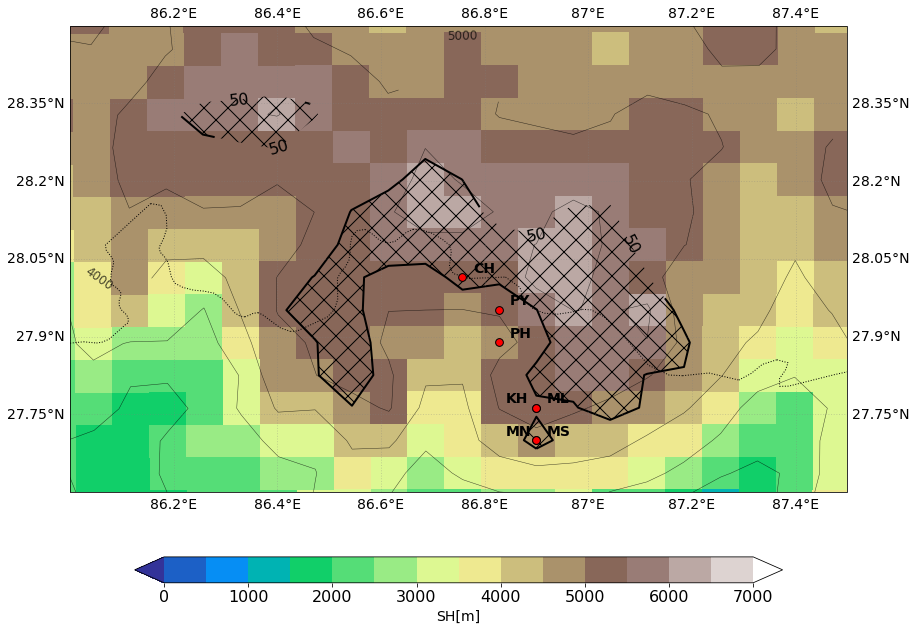

In [14]:
clevs=np.arange(0,7500,500)
cmap_mod = plt.get_cmap('terrain')
norm = mcolors.BoundaryNorm(boundaries=clevs, ncolors=cmap_mod.N, extend="both")

fig, ax = plt.subplots(figsize=(18, 12),
                         subplot_kw={'projection': ccrs.PlateCarree()})


im = ax.pcolormesh(LONS,LATS,dsSH,
                       transform=ccrs.PlateCarree(), cmap=cmap_mod,norm=norm,shading='auto')
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
#ax.set_title(f'Month {i+1}')

ICE1=ax.contourf(LONS, LATS,dsICE,
            levels=[10,50,100],
            hatches=['','X','X'],
            colors="none",
            transform=ccrs.PlateCarree())

#    ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', linestyle='--')
ax.set_aspect(1.0)
SH1 = ax.contour(LONS, LATS, dsSH,
                             levels=[1000,2000,3000,4000,5000,6000,7000],
                             colors="k", linewidths=0.5, alpha=0.7,
                             transform=ccrs.PlateCarree())
ax.clabel(SH1, inline=True, fontsize=12, fmt="%d")
    
ICE2= ax.contour(LONS, LATS, dsICE,
                    levels=[50],
                    colors="black", linewidths=2.0, alpha=1.0,
                    transform=ccrs.PlateCarree())

ax.clabel(ICE2, inline=True, fontsize=16, fmt="%d")
#iso= ax.contour(LONS, LATS, annual_clim,
#                    levels=[0],
#                    colors="blue", linewidths=2.0, alpha=1.0,
#                    transform=ccrs.PlateCarree())

ax.clabel(ICE2, inline=True, fontsize=16, fmt="%d")
#ax.set_extent([85, 115, 60, 35], crs=ccrs.PlateCarree())
ax.set_extent([86, 87.5, 27.6, 28.5], crs=ccrs.PlateCarree())

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                          linewidth=1, color="gray", alpha=0.3, linestyle=":")
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}

stations = {
    "MS": (jMS, iMS),
    "MN": (jMN, iMN),
    "ML": (jML, iML),
    "CH": (jCH, iCH),
    "PY": (jPY, iPY),
    "KH": (jKH, iKH),
    "PH": (jPH, iPH)
}

# Loop over stations and plot them
for name, (j, i) in stations.items():
    lon = LONS[j, i]
    lat = LATS[j, i]

    ax.scatter(lon, lat, color="red", s=60, edgecolor="black", zorder=5,
               transform=ccrs.PlateCarree())

    # Handle overlapping stations
    if (j, i) == (27, 70):
        if name == "MS":
            ax.text(lon + 0.02, lat + 0.01, name, color="black", fontsize=14,
                    weight='bold', transform=ccrs.PlateCarree(), zorder=6)
        else:  # MN
            ax.text(lon - 0.06, lat + 0.01, name, color="black", fontsize=14,
                    weight='bold', transform=ccrs.PlateCarree(), zorder=6)
    elif (j, i) == (28, 70):
        if name == "ML":
            ax.text(lon + 0.02, lat + 0.01, name, color="black", fontsize=14,
                    weight='bold', transform=ccrs.PlateCarree(), zorder=6)
        else:  # KH
            ax.text(lon - 0.06, lat + 0.01, name, color="black", fontsize=14,
                    weight='bold', transform=ccrs.PlateCarree(), zorder=6)
    else:
        # Default for non-overlapping stations
        ax.text(lon + 0.02, lat + 0.01, name, color="black", fontsize=14,
                weight='bold', transform=ccrs.PlateCarree(), zorder=6)
    

# Add a single colorbar for all subplots

cbar_ax = fig.add_axes([0.25, 0.15, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label(f"{'SH'}[{'m'}]", fontsize=14)
cbar.ax.tick_params(labelsize=16)

fig.subplots_adjust(left=0.2, right=0.8, top=0.95, bottom=0.1, wspace=0.05, hspace=0.2)
#plt.tight_layout()
#plt.suptitle(f'Annual mean ({iyr}-{fyr})',fontsize=18,y=0.87)
plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"

plotname=f'fig9_map_glacioclim_MAR.{domain}_SH_ICE_nepal_zoom'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()

In [15]:
stations

{'MS': (27, 70),
 'MN': (27, 70),
 'ML': (28, 70),
 'CH': (32, 68),
 'PY': (31, 69),
 'KH': (28, 70),
 'PH': (30, 69)}

In [16]:
ts_RF_PH=ds_RF[:,jPH,iPH].sel(time=slice(idatePH,fdatePH))
ts_SF_PH=ds_SF[:,jPH,iPH].sel(time=slice(idatePH,fdatePH))
ts_TF_PH=ts_RF_PH+ts_SF_PH

ts_RF_KH=ds_RF[:,jKH,iKH].sel(time=slice(idateKH,fdateKH))
ts_SF_KH=ds_SF[:,jKH,iKH].sel(time=slice(idateKH,fdateKH))
ts_TF_KH=ts_RF_KH+ts_SF_KH


ts_RF_PY=ds_RF[:,jPY,iPY].sel(time=slice(idatePY,fdatePY))
ts_SF_PY=ds_SF[:,jPY,iPY].sel(time=slice(idatePY,fdatePY))
ts_TF_PY=ts_RF_PY+ts_SF_PY


In [17]:
from scipy.stats import pearsonr

ts_PY=RR_daily_PY.RRYhourly
rmse_PY = np.sqrt(np.mean((ts_TF_PY.values - ts_PY.values)**2))
bias_PY = np.mean(ts_TF_PY.values - ts_PY.values)
corr_PY = pearsonr(ts_TF_PY.values, ts_PY.values)[0]

print(f" PY= RMSE: {rmse_PY:.3f}, Bias: {bias_PY:.3f}, Correlation: {corr_PY:.3f}")


ts_PH=RR_daily_PH.RRHhourly
rmse_PH = np.sqrt(np.mean((ts_TF_PH.values - ts_PH.values)**2))
bias_PH = np.mean(ts_TF_PH.values - ts_PH.values)
corr_PH = pearsonr(ts_TF_PH.values, ts_PH.values)[0]

print(f" PH= RMSE: {rmse_PH:.3f}, Bias: {bias_PH:.3f}, Correlation: {corr_PH:.3f}")


ts_KH=RR_daily_KH.RRhourly
rmse_KH = np.sqrt(np.mean((ts_TF_KH.values - ts_KH.values)**2))
bias_KH = np.mean(ts_TF_KH.values - ts_KH.values)
corr_KH = pearsonr(ts_TF_KH.values, ts_KH.values)[0]

print(f" KH= RMSE: {rmse_KH:.3f}, Bias: {bias_KH:.3f}, Correlation: {corr_KH:.3f}")


 PY= RMSE: 5.081, Bias: 1.665, Correlation: 0.445
 PH= RMSE: 5.072, Bias: 1.620, Correlation: 0.448
 KH= RMSE: 7.461, Bias: 2.847, Correlation: 0.397


In [18]:

ts_PY=RR_daily_PY.RRYhourly
ts_PY

<xarray.DataArray 'RRYhourly' (time: 4008)>
array([0., 0., 0., ..., 0., 0., 0.])
Coordinates:
  * time     (time) datetime64[ns] 2012-12-06 2012-12-07 ... 2023-11-26

In [19]:
ts_model.values

NameError: name 'ts_model' is not defined

In [ ]:
corr = np.corrcoef(ts_model.values, ts_obs.values)[1]
print(corr)

In [ ]:
ac_KH=RR_daily_KH.groupby('time.month').mean()
ac_PH=RR_daily_PH.groupby('time.month').mean()
ac_PY=RR_daily_PY.groupby('time.month').mean()

ac_KH=ac_KH.RRhourly#RR_daily_KH.groupby('time.month').mean()
ac_PH=ac_PH.RRHhourly#RR_daily_PH.groupby('time.month').mean()
ac_PY=ac_PY.RRYhourly#RR_daily_PY.groupby('time.month').mean()


In [ ]:
ac_TF_KH=ts_TF_KH.groupby('time.month').mean()
ac_TF_PH=ts_TF_PH.groupby('time.month').mean()
ac_TF_PY=ts_TF_PY.groupby('time.month').mean()

ac_RF_KH=ts_RF_KH.groupby('time.month').mean()
ac_RF_PH=ts_RF_PH.groupby('time.month').mean()
ac_RF_PY=ts_RF_PY.groupby('time.month').mean()

ac_SF_KH=ts_SF_KH.groupby('time.month').mean()
ac_SF_PH=ts_SF_PH.groupby('time.month').mean()
ac_SF_PY=ts_SF_PY.groupby('time.month').mean()


In [ ]:
plotList_MAR=[ac_TF_KH,ac_TF_PH,ac_TF_PY]
plotList_sta=[ac_KH,ac_PH,ac_PY]

In [ ]:

months = np.arange(1, 13)
month_labels = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']

SF = ac_SF_KH#['SF']
RF = ac_RF_KH#[#'RF']
STA = ac_KH

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(months, RF, color='blue', label='MAR-Rain)')
ax.bar(months, SF, bottom=RF, color='lightblue', label='MAR-Snow')

# Station line
ax.plot(months, STA, color='k', marker='o', label='Station')

# Labels and aesthetics
ax.set_xticks(months)
ax.set_xticklabels(month_labels)
ax.set_title('KH – Monthly Precipitation')
ax.set_ylabel('Precipitation [mm/month]')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend()

plt.tight_layout()

plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Example structure: adjust according to your variables
# ac_TF_KH = {'SF': sf_KH, 'RF': rf_KH}  # each length-12 array
# ac_KH = obs_KH                          # length-12 array

stations = ['Khare', 'Pheriche', 'Pyramide']
ac_TF = [ac_TF_KH, ac_TF_PH, ac_TF_PY]
ac_RF = [ac_RF_KH, ac_RF_PH, ac_RF_PY]
ac_SF = [ac_SF_KH, ac_SF_PH, ac_SF_PY]

ac_sta = [ac_KH, ac_PH, ac_PY]

months = np.arange(1, 13)
month_labels = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']

fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

for i, ax in enumerate(axes):
    # Extract data
    SF = ac_SF[i]
    RF = ac_RF[i]
    STA = ac_sta[i]

    ax.bar(months, RF, color='blue', alpha=0.5,label='MAR-Rainfall')
    ax.bar(months, SF, bottom=RF, color='lightblue', label='MAR-Snowfall')

    # Plot station line
    ax.plot(months, STA, color='k', marker='o', label=stations[i])

    ax.set_title(stations[i])
    ax.set_ylabel('Precipitation [mm/month]')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend()

axes[-1].set_xticks(months)
axes[-1].set_xticklabels(month_labels)
axes[-1].set_xlabel('Month')

plt.tight_layout()
plt.show()


In [ ]:
# 1) monthly totals per monthly period (mm)
#pr_monthly_totals = pr.resample(time="M").sum()

# 2) monthly climatology (mean of each calendar month across years)
#monthly_climatology_totals = pr_monthly_totals.groupby("time.month").mean("time")
# result: DataArray with 12 values (month dimension), units mm (monthly total)

# Optional: spread (std) across years
#monthly_std_totals = pr_monthly_totals.groupby("time.month").std("time")

In [ ]:
KH_cum=RR_daily_KH.resample(time="M").sum().RRhourly
PH_cum=RR_daily_PH.resample(time="M").sum().RRHhourly
PY_cum=RR_daily_PY.resample(time="M").sum().RRYhourly

ac_KH_cum=KH_cum.groupby("time.month").mean("time")
ac_PY_cum=PY_cum.groupby("time.month").mean("time")
ac_PH_cum=PH_cum.groupby("time.month").mean("time")

In [ ]:

ac_TF_KH_cum=ts_TF_KH.resample(time="M").sum().groupby('time.month').mean("time")
ac_TF_PH_cum=ts_TF_PH.resample(time="M").sum().groupby('time.month').mean("time")
ac_TF_PY_cum=ts_TF_PY.resample(time="M").sum().groupby('time.month').mean("time")

In [ ]:
ac_RF_KH_cum=ts_RF_KH.resample(time="M").sum().groupby('time.month').mean("time")
ac_RF_PH_cum=ts_RF_PH.resample(time="M").sum().groupby('time.month').mean("time")
ac_RF_PY_cum=ts_RF_PY.resample(time="M").sum().groupby('time.month').mean("time")

ac_SF_KH_cum=ts_SF_KH.resample(time="M").sum().groupby('time.month').mean("time")
ac_SF_PH_cum=ts_SF_PH.resample(time="M").sum().groupby('time.month').mean("time")
ac_SF_PY_cum=ts_SF_PY.resample(time="M").sum().groupby('time.month').mean("time")


In [ ]:

stations = ['Khare', 'Pheriche', 'Pyramide']
ac_TF = [ac_TF_KH_cum, ac_TF_PH_cum, ac_TF_PY_cum]
ac_RF = [ac_RF_KH_cum, ac_RF_PH_cum, ac_RF_PY_cum]
ac_SF = [ac_SF_KH_cum, ac_SF_PH_cum, ac_SF_PY_cum]

ac_sta = [ac_KH_cum, ac_PH_cum, ac_PY_cum]

months = np.arange(1, 13)
month_labels = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']

fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

for i, ax in enumerate(axes):
    # Extract data
    SF = ac_SF[i]
    RF = ac_RF[i]
    STA = ac_sta[i]

    ax.bar(months, RF, color='blue', alpha=0.5,label='MAR-Rainfall')
    ax.bar(months, SF, bottom=RF, color='lightblue', label='MAR-Snowfall')

    # Plot station line
    ax.plot(months, STA, color='k', marker='o', label=stations[i])

    ax.set_title(stations[i])
    ax.set_ylabel('Pre cum[mm/month]')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend()

axes[-1].set_xticks(months)
axes[-1].set_xticklabels(month_labels)
axes[-1].set_xlabel('Month')

plt.tight_layout()
plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"

plotname=f'fig9_annual_cycle_pre_cum.stations_glaciolim_MAR'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()
